# Malicious URL Classification — Full Pipeline
Run all cells top-to-bottom. Trains LR, SVM, RF, XGBoost and reports Accuracy/Precision/Recall/F1 + ROC curves.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, joblib
from features import extract_all, ALL_COLS, LEXICAL_COLS, HOST_COLS
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, auc, classification_report, ConfusionMatrixDisplay, confusion_matrix)
import warnings; warnings.filterwarnings('ignore')
print('imports ok')

imports ok


## 1. Load & clean dataset

In [2]:
rows=[]
with open('dephides/dataset/small_dataset/train.txt') as f:
    for line in f:
        line=line.rstrip('\n')
        if not line.strip(): continue
        parts=line.split('\t')
        if len(parts)!=2: parts=line.split()
        if len(parts)!=2: continue
        rows.append(parts)
df=pd.DataFrame(rows, columns=['label','url'])
print('shape', df.shape)
print(df['label'].value_counts())

shape (364198, 2)
label
legitimate    201736
phishing      162462
Name: count, dtype: int64


## 2. Feature engineering

In [3]:
sample=df.sample(n=20000, random_state=42).reset_index(drop=True)
X=pd.DataFrame([extract_all(u) for u in sample['url']])[ALL_COLS]
y=(sample['label']=='phishing').astype(int).values
print('X', X.shape, 'y', y.shape)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler=StandardScaler()
Xtr_s=scaler.fit_transform(Xtr); Xte_s=scaler.transform(Xte)
print('split done')

X (20000, 40) y (20000,)
split done


## 3. Train models & evaluate

LogisticRegression: acc=0.9285 prec=0.9276 rec=0.9110 f1=0.9192 auc=0.9815


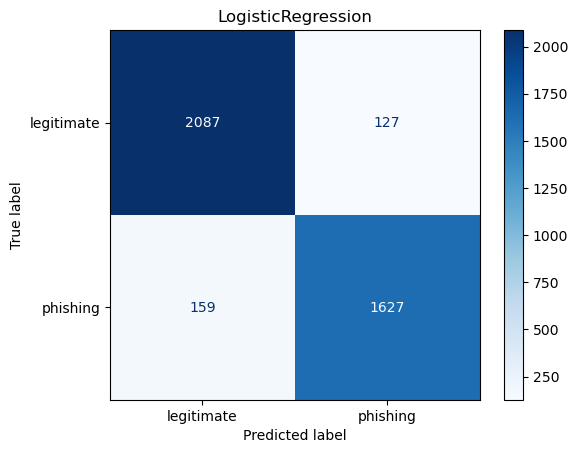

SVM (RBF): acc=0.9433 prec=0.9357 rec=0.9373 f1=0.9365 auc=0.9870


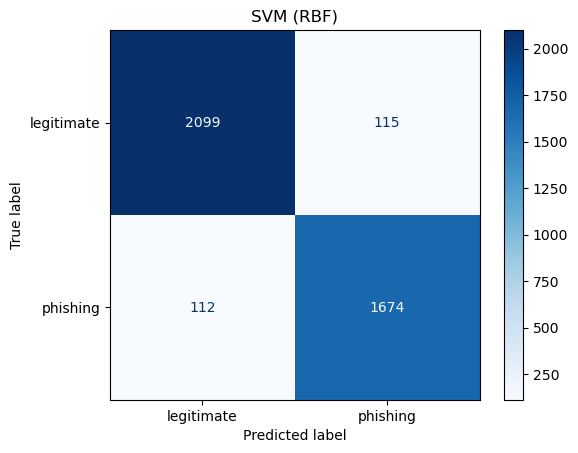

RandomForest: acc=0.9420 prec=0.9365 rec=0.9334 f1=0.9349 auc=0.9871


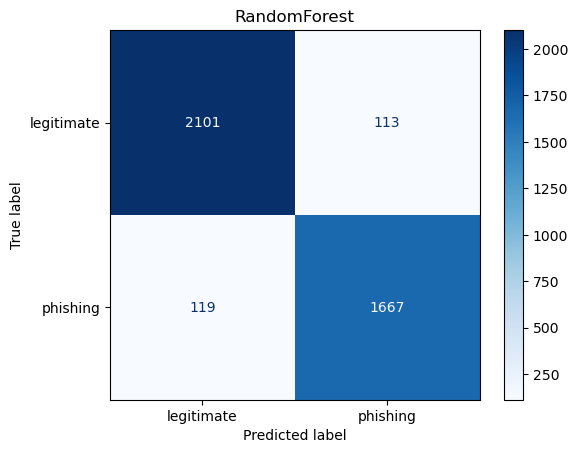

XGBoost: acc=0.9437 prec=0.9422 rec=0.9311 f1=0.9366 auc=0.9894


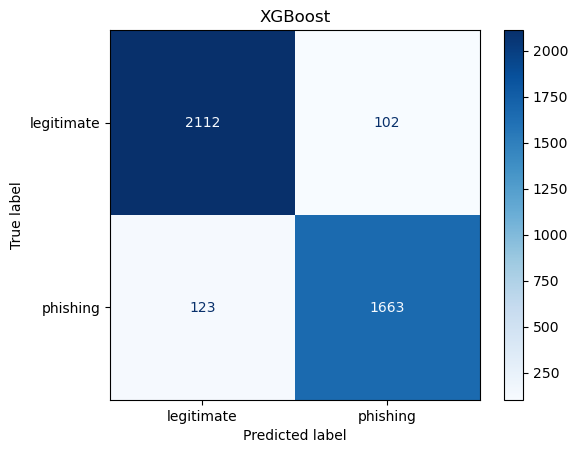

,model,accuracy,precision,recall,f1,auc
0,LogisticRegression,0.92850,0.927594,0.910974,0.919209,0.981459
1,SVM (RBF),0.94325,0.935718,0.937290,0.936503,0.986985
2,RandomForest,0.94200,0.936517,0.933371,0.934941,0.987119
3,XGBoost,0.94375,0.942210,0.931131,0.936638,0.989401


In [4]:
models={
 'LogisticRegression': LogisticRegression(max_iter=1000),
 'SVM (RBF)': SVC(kernel='rbf', probability=True),
 'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
 'XGBoost': XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss', n_jobs=-1),
}
results=[]
for name,m in models.items():
    if name in ('LogisticRegression','SVM (RBF)'):
        m.fit(Xtr_s,ytr); pred=m.predict(Xte_s); proba=m.predict_proba(Xte_s)[:,1]
    else:
        m.fit(Xtr,ytr); pred=m.predict(Xte); proba=m.predict_proba(Xte)[:,1]
    acc=accuracy_score(yte,pred); prec=precision_score(yte,pred)
    rec=recall_score(yte,pred); f1=f1_score(yte,pred)
    fpr,tpr,_=roc_curve(yte,proba); roc_auc=auc(fpr,tpr)
    results.append({'model':name,'accuracy':acc,'precision':prec,'recall':rec,'f1':f1,'auc':roc_auc,'fpr':fpr,'tpr':tpr})
    print(f'{name}: acc={acc:.4f} prec={prec:.4f} rec={rec:.4f} f1={f1:.4f} auc={roc_auc:.4f}')
    ConfusionMatrixDisplay(confusion_matrix(yte,pred),display_labels=['legitimate','phishing']).plot(cmap='Blues')
    plt.title(name); plt.show()
pd.DataFrame(results)[['model','accuracy','precision','recall','f1','auc']]

## 4. ROC curves

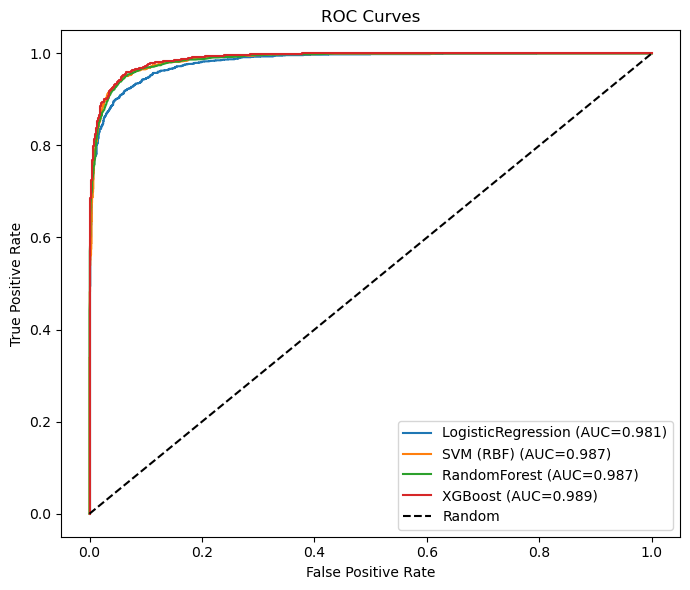

In [5]:
fig,ax=plt.subplots(figsize=(7,6))
for r in results:
    ax.plot(r['fpr'],r['tpr'],label=f"{r['model']} (AUC={r['auc']:.3f})")
ax.plot([0,1],[0,1],'k--',label='Random')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves'); ax.legend(); plt.tight_layout(); plt.show()

## 5. Save model 

In [6]:
best=XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss', n_jobs=-1)
best.fit(X,y)
joblib.dump({'model':best,'features':ALL_COLS,'scaler':None},'model.pkl')
print('saved model.pkl (XGBoost on full sample)')

saved model.pkl (XGBoost on full sample)


In [ ]:
import joblib, pandas as pd
from features import extract_all, ALL_COLS

bundle = joblib.load('model.pkl')
model = bundle['model']
features = bundle['features']

while True:
    url = input("Enter URL (or 'exit' to quit): ").strip()
    if not url or url.lower() in ('exit', 'quit', 'q'):
        print("Bye!")
        break
    feats = pd.DataFrame([extract_all(url)])[features]
    pred = model.predict(feats)[0]
    prob = model.predict_proba(feats)[0][pred]
    print("malicious" if pred == 1 else "LEGITIMATE (safe)", f"({prob:.2%})")
    print()

Enter URL (or 'exit' to quit): gfhj
malicious (98.28%)

